In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

file_path = r"C:\Users\ashun\Downloads\flight_data_2024_final_cleaned.csv"
df = pd.read_csv(file_path, low_memory=False)

# Select numerical features relevant to flight operations
features = [
    "dep_delay", "arr_delay", "taxi_out",
    "taxi_in", "air_time", "distance",
    "crs_elapsed_time", "actual_elapsed_time"
]

# Use a sample to make PCA efficient
pca_df = df[features].dropna().sample(
    n=50000, random_state=42
)

print("Selected features:", features)
print("PCA dataset shape:", pca_df.shape)

# Standardize before PCA
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_df)

# Fit PCA
pca = PCA()
pca_result = pca.fit_transform(scaled_data)

variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

print("\nExplained variance ratio:")
print(np.round(variance, 4))

print("\nCumulative explained variance:")
print(np.round(cumulative_variance, 4))

components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("\nComponents needed for 95% variance:", components_95)


Selected features: ['dep_delay', 'arr_delay', 'taxi_out', 'taxi_in', 'air_time', 'distance', 'crs_elapsed_time', 'actual_elapsed_time']
PCA dataset shape: (50000, 8)

Explained variance ratio:
[0.4953 0.25   0.1238 0.1222 0.0053 0.0028 0.0005 0.    ]

Cumulative explained variance:
[0.4953 0.7453 0.8691 0.9914 0.9966 0.9995 1.     1.    ]

Components needed for 95% variance: 4


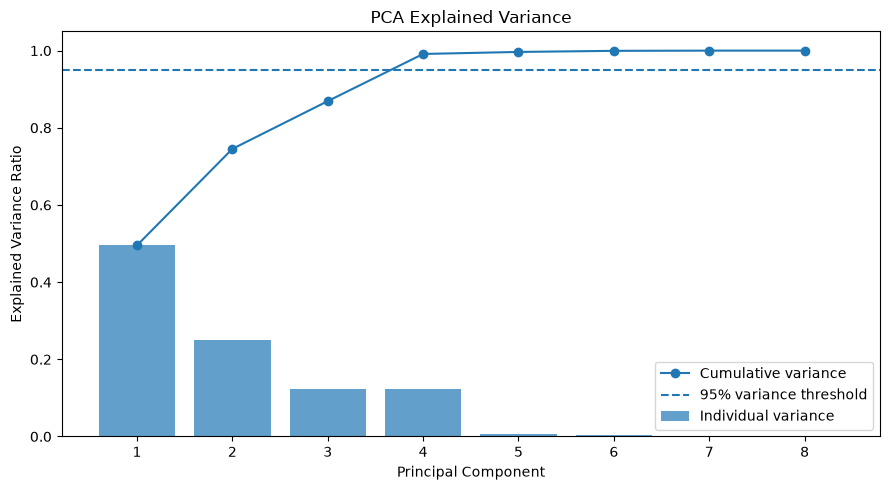

In [2]:

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(variance) + 1),
    variance,
    alpha=0.7,
    label="Individual variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    label="Cumulative variance"
)

plt.axhline(y=0.95, linestyle="--",
            label="95% variance threshold")

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.xticks(range(1, len(variance) + 1))
plt.legend()
plt.tight_layout()
plt.show()


# Week 7: Dimensionality Reduction

## Findings
- Selected eight numerical flight features for analysis.
- Standardized the features before applying PCA.
- Calculated individual and cumulative explained variance.
- Visualized the contribution of each principal component.
- Identified the number of components required to retain at least 95% of the variance.

## Conclusion
PCA transforms correlated numerical features into principal components while retaining as much information as possible. This experiment uses a random sample of 50,000 flights for computational efficiency.